# SSVEP: os dados do dataset AVI

Estrutura dos dados do AVI SSVEP Dataset (www.setzner.com, parte *single-target*) e comparação entre os 4 participantes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# lê os arquivos dos 4 participantes
participantes = {}
for p in [1, 2, 3, 4]:
    participantes[p] = loadmat(f"dados/Sub{p}_singletarget.mat")["Data"][0][0]

## Como os dados funcionam

In [2]:
d = participantes[1]
eeg = d["EEG"]
freqs = d["TargetFrequency"].ravel()
fs = d["AmpSamplingFrequency"][0][0]

print("Formato do EEG:", eeg.shape)
print("Taxa de amostragem:", fs, "Hz")
print("Frequência de cada gravação:", freqs)

Formato do EEG: (15360, 27)
Taxa de amostragem: 512 Hz
Frequência de cada gravação: [10.  10.  10.  12.  12.  12.   6.5  6.5  6.5  6.   6.   6.   6.   6.
  6.   7.5  7.5  7.5  7.   7.   7.   8.2  8.2  8.2  9.3  9.3  9.3]


O `EEG` é uma tabela de 15360 linhas × 27 colunas.

Cada coluna é uma gravação: 30 segundos em que a pessoa olhou para uma luz piscando.

Cada linha é uma medição da eletricidade do cérebro. O aparelho mede 512 vezes por segundo: 512 × 30 s = 15360 linhas.

O `TargetFrequency` diz para qual luz a pessoa olhava em cada gravação (o rótulo). A posição 1 da lista corresponde à coluna 1 do EEG, e assim por diante.

### O EEG visto como tabela

Um pedaço da tabela do participante 1.

In [3]:
import pandas as pd

linhas = [0, 1, 2, 3, 4, 5, 15359]   # 6 primeiras linhas e a última
colunas = [0, 1, 2, 3, 26]           # 4 primeiras gravações e a última

tabela = pd.DataFrame(
    eeg[np.ix_(linhas, colunas)] * 1e6,   # volts -> microvolts
    index=[f"Linha {l + 1} ({l / fs:.3f} s)" for l in linhas],
    columns=[f"Gravação {c + 1} ({freqs[c]:g} Hz)" for c in colunas],
).round(2)
tabela

,Gravação 1 (10 Hz),Gravação 2 (10 Hz),Gravação 3 (10 Hz),Gravação 4 (12 Hz),Gravação 27 (9.3 Hz)
Linha 1 (0.000 s),2.60,9.17,-8.07,-5.34,12.77
Linha 2 (0.002 s),2.70,9.18,-9.40,-5.48,11.85
Linha 3 (0.004 s),2.81,8.52,-10.49,-5.39,10.82
Linha 4 (0.006 s),2.95,7.32,-11.33,-5.04,9.74
Linha 5 (0.008 s),3.12,5.74,-11.92,-4.40,8.61
Linha 6 (0.010 s),3.32,4.00,-12.28,-3.48,7.43
Linha 15360 (29.998 s),-3.63,12.75,-15.32,2.90,9.53


Exemplo: os 2 primeiros segundos da primeira gravação.

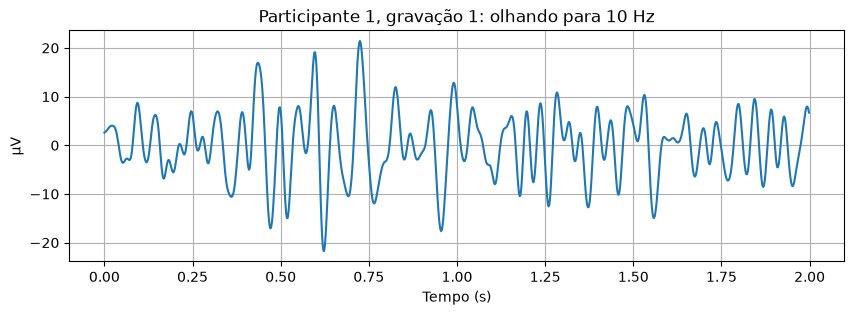

In [4]:
t = np.arange(eeg.shape[0]) / fs   # número da linha ÷ 512 = segundos
trecho = t < 2

plt.figure(figsize=(10, 3))
plt.plot(t[trecho], eeg[trecho, 0] * 1e6)   # volts -> microvolts
plt.xlabel("Tempo (s)")
plt.ylabel("µV")
plt.title(f"Participante 1, gravação 1: olhando para {freqs[0]:g} Hz")
plt.grid(True)
plt.show()

## Os 4 participantes

In [5]:
print(f"{'Participante':<14}{'Sexo':<6}{'Idade':<7}{'Gravações'}")
for p, d in participantes.items():
    print(f"{p:<14}{d['SubjectGender'][0]:<6}{d['SubjectAge'][0]:<7}{d['EEG'].shape[1]}")

Participante  Sexo  Idade  Gravações
1             M     32     27
2             M     27     26
3             M     27     21
4             F     31     21


### Quantas gravações de cada frequência

In [6]:
todas_freqs = np.unique(np.concatenate(
    [d["TargetFrequency"].ravel() for d in participantes.values()]))

print(f"{'Frequência':<12}" + "".join(f"Part. {p:<4}" for p in participantes))
for f in todas_freqs:
    linha = f"{f:g} Hz".ljust(12)
    for d in participantes.values():
        linha += str(np.sum(d["TargetFrequency"].ravel() == f)).ljust(10)
    print(linha)

Frequência  Part. 1   Part. 2   Part. 3   Part. 4   
6 Hz        6         3         3         3         
6.5 Hz      3         4         3         3         
7 Hz        3         6         3         3         
7.5 Hz      3         3         3         3         
8.2 Hz      3         4         3         3         
9.3 Hz      3         3         3         3         
10 Hz       3         3         3         3         
12 Hz       3         0         0         0         


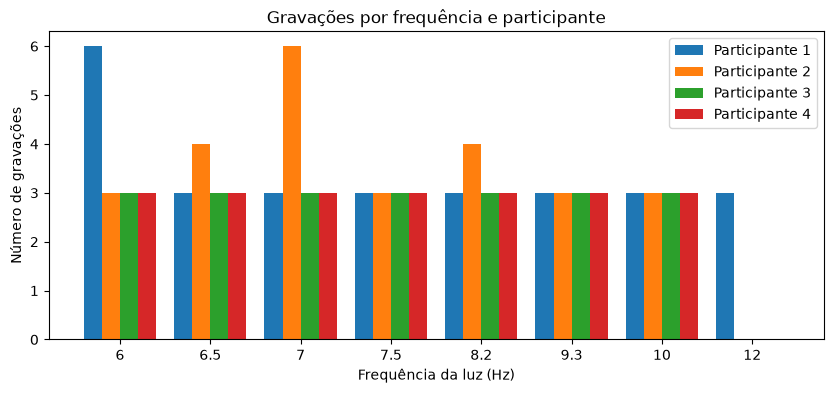

In [7]:
largura = 0.2
x = np.arange(len(todas_freqs))

plt.figure(figsize=(10, 4))
for i, (p, d) in enumerate(participantes.items()):
    contagem = [np.sum(d["TargetFrequency"].ravel() == f) for f in todas_freqs]
    plt.bar(x + i * largura, contagem, width=largura, label=f"Participante {p}")

plt.xticks(x + 1.5 * largura, [f"{f:g}" for f in todas_freqs])
plt.xlabel("Frequência da luz (Hz)")
plt.ylabel("Número de gravações")
plt.title("Gravações por frequência e participante")
plt.legend()
plt.show()

### Ordem das gravações

A tabela acima está organizada da menor para a maior frequência só para facilitar a leitura. A ordem real das gravações é a mesma para todos: 10 → 6,5 → 6 → 7,5 → 7 → 8,2 → 9,3 Hz.

### O sinal de cada participante olhando para a mesma luz (10 Hz)

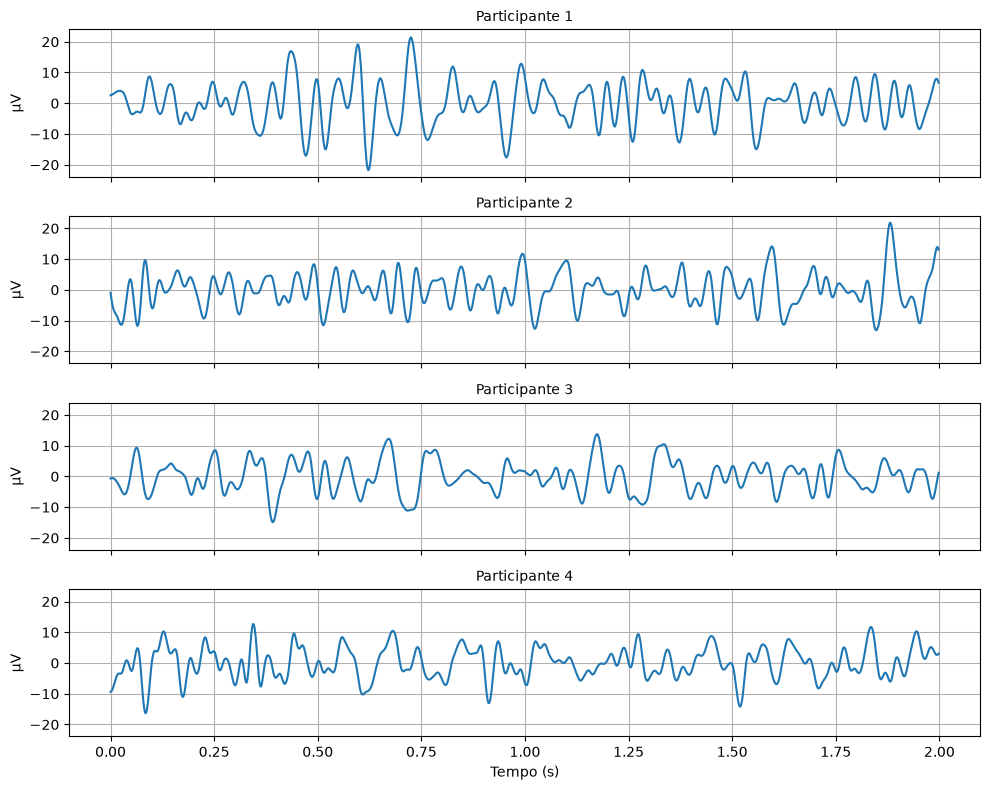

In [8]:
fig, eixos = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, (p, d) in zip(eixos, participantes.items()):
    i = np.where(d["TargetFrequency"].ravel() == 10)[0][0]   # 1ª gravação de 10 Hz
    ax.plot(t[trecho], d["EEG"][trecho, i] * 1e6)
    ax.set_title(f"Participante {p}", fontsize=10)
    ax.set_ylabel("µV")
    ax.grid(True)

eixos[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()